In [ ]:
import os

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from models.kan_layer import *

In [ ]:
print("--- Demostración de la Capa DenseKAN vs. MLP Estándar ---")

X_train = np.linspace(-1, 1, 1000).reshape(-1, 1).astype(np.float32)
y_train = np.sin(2 * np.pi * X_train) + 0.2 * np.cos(5 * np.pi * X_train) + X_train**3
X_test = np.linspace(-1, 1, 200).reshape(-1, 1).astype(np.float32)
y_test = np.sin(2 * np.pi * X_test) + 0.2 * np.cos(5 * np.pi * X_test) + X_test**3

# --- Construcción de modelos con la API Funcional para evitar conflictos ---

--- Demostración de la Capa DenseKAN vs. MLP Estándar ---


In [ ]:
# Modelo KAN
kan_input = tf.keras.Input(shape=(1,), name="input_kan")
x1 = DenseKAN(units=3, name='kan_1', grid_size=10, spline_order=3, grid_range = [-1,1], track_inputs=True)(kan_input)
kan_output = DenseKAN(units=1, name='kan_2', grid_size=10, spline_order=3, grid_range = [-1,1], track_inputs=True)(x1)
kan_model = tf.keras.Model(inputs=kan_input, outputs=kan_output, name="kan_model")

# Modelo MLP
mlp_input = tf.keras.Input(shape=(1,), name="input_mlp")
y1 = tf.keras.layers.Dense(64, activation='relu')(mlp_input)
y2 = tf.keras.layers.Dense(16, activation='relu')(y1)
mlp_output = tf.keras.layers.Dense(1)(y2)
mlp_model = tf.keras.Model(inputs=mlp_input, outputs=mlp_output, name="mlp_model")

# Modelo MLP BIG
mlp_input_big = tf.keras.Input(shape=(1,), name="input_mlp_big")
y1 = tf.keras.layers.Dense(512, activation='relu')(mlp_input_big)
y2 = tf.keras.layers.Dense(256, activation='relu')(y1)
y3 = tf.keras.layers.Dense(54, activation='relu')(y2)
mlp_output_big = tf.keras.layers.Dense(1)(y3)
mlp_model_big = tf.keras.Model(inputs=mlp_input_big, outputs=mlp_output_big, name="mlp_model_big")

print("\n--- Comparación de Parámetros ---")
kan_model.summary()
mlp_model.summary()
mlp_model_big.summary()


--- Comparación de Parámetros ---


Model: "kan_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_kan (InputLayer)          │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ kan_1 (DenseKAN)                │ (None, 3)              │         4,162 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ kan_2 (DenseKAN)                │ (None, 1)              │        12,356 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,518 (64.54 KB)

 Trainable params: 88 (352.00 B)

...

Model: "mlp_model_big"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_mlp_big (InputLayer)      │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 54)             │        13,878 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            55 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 146,285 (571.43 KB)

 Trainable params: 146,285 (571.43 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
grid_cb = DenseKANAutoGridUpdate(
    model_with_kan=kan_model,
    on_epoch_end=True,
    min_required=256,
    margin=0.05, grid_eps=0.02, l2_reg=1e-6, fast=True
)

In [ ]:
print("\nEntrenando modelos...")
kan_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
mlp_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
mlp_model_big.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')

kan_model.fit(X_train, y_train, callbacks=[grid_cb], epochs=100, batch_size=64, verbose=1)
mlp_model.fit(X_train, y_train, epochs=100, batch_size=64, verbose=1)
mlp_model_big.fit(X_train, y_train, epochs=100, batch_size=64, verbose=1)
print("Entrenamiento completado.")

kan_loss = kan_model.evaluate(X_test, y_test, verbose=0)
mlp_loss = mlp_model.evaluate(X_test, y_test, verbose=0)
mlp_loss_big = mlp_model_big.evaluate(X_test, y_test, verbose=0)
print(f"\nError Cuadrático Medio Final (KAN): {kan_loss:.6f}")
print(f"Error Cuadrático Medio Final (MLP): {mlp_loss:.6f}")
print(f"Error Cuadrático Medio Final (MLP BIG): {mlp_loss_big:.6f}")


Entrenando modelos...
Epoch 1/100
 1/16 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - loss: 0.4176Updating_grid
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.4315
Epoch 2/100
 1/16 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 0.4266Updating_grid
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4371
Epoch 3/100
 1/16 ━━━━━━━━━━━━━━━━━━━━ 2s 143ms/step - loss: 0.4468Updating_grid
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.3802 
Epoch 4/100
 1/16 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - loss: 0.3276Updating_grid
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3336 
Epoch 5/100
 1/16 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - loss: 0.3774Updating_grid
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3177 
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2731  Updating_grid
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2729
Epoch 7/100
 1/16 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.2511Updating_grid
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2460
Epoch 8/100
 1/16 ━━━━━━━━

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


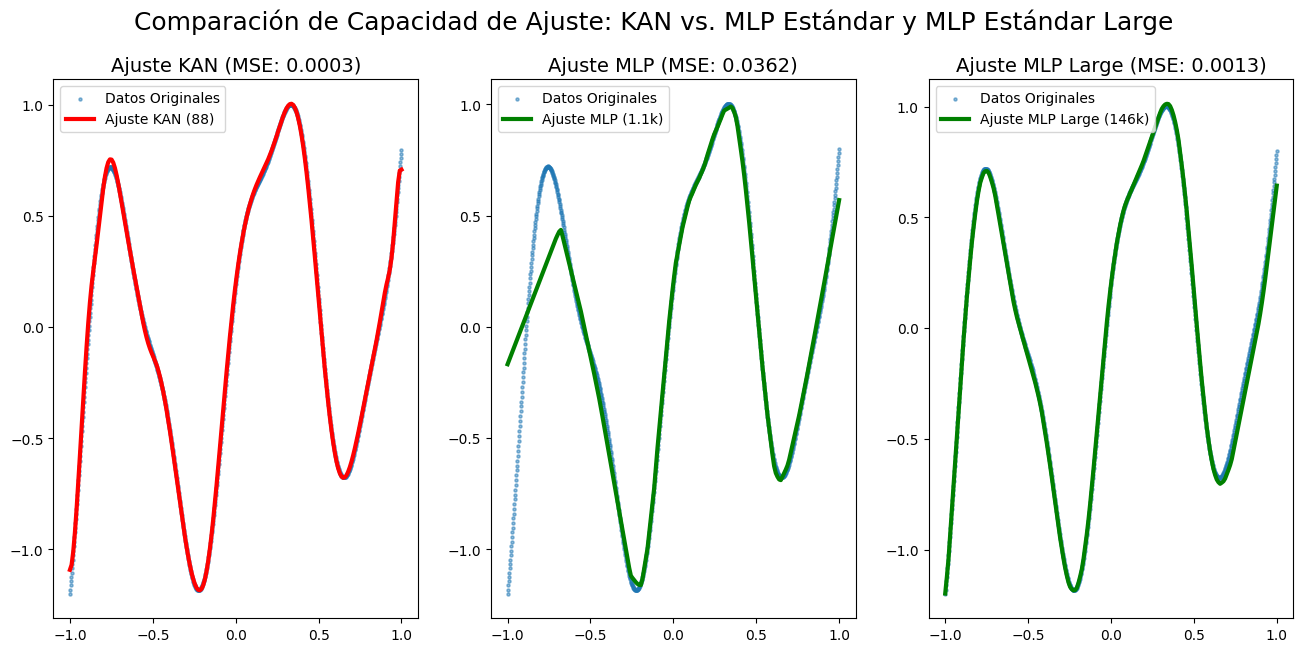

In [ ]:
plt.figure(figsize=(16, 7))
plt.subplot(1, 3, 1)
plt.scatter(X_train, y_train, s=5, label='Datos Originales', alpha=0.5)
plt.plot(X_test, kan_model.predict(X_test), color='red', linewidth=3, label='Ajuste KAN (88)')
plt.title(f'Ajuste KAN (MSE: {kan_loss:.4f})', fontsize=14)
plt.legend()

plt.subplot(1, 3, 2)
plt.scatter(X_train, y_train, s=5, label='Datos Originales', alpha=0.5)
plt.plot(X_test, mlp_model.predict(X_test), color='green', linewidth=3, label='Ajuste MLP (1.1k)')
plt.title(f'Ajuste MLP (MSE: {mlp_loss:.4f})', fontsize=14)
plt.legend()

plt.subplot(1, 3, 3)
plt.scatter(X_train, y_train, s=5, label='Datos Originales', alpha=0.5)
plt.plot(X_test, mlp_model_big.predict(X_test), color='green', linewidth=3, label='Ajuste MLP Large (146k)')
plt.title(f'Ajuste MLP Large (MSE: {mlp_loss_big:.4f})', fontsize=14)
plt.legend()

plt.suptitle("Comparación de Capacidad de Ajuste: KAN vs. MLP Estándar y MLP Estándar Large", fontsize=18)
plt.show()